## 1. Setup – Mount Google Drive and Configure Paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os

PROJECT_ROOT = '/content/drive/MyDrive/Binary Image Segmentation'
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

os.chdir(PROJECT_ROOT)
print(f"Working directory: {os.getcwd()}")


## 2. Environment Check

In [1]:
import sys, torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on: {device}")


Python: c:\Users\adith\AppData\Local\Programs\Python\Python312\python.exe
PyTorch: 2.14.1+cu126
CUDA build: 12.6
CUDA available: True
Training on: cuda


## 3. Configuration

In [2]:
from src.config import (
    IMAGE_DIR, MASK_DIR, CHECKPOINT_DIR, OUTPUT_DIR,
    IMG_SIZE, BATCH_SIZE, VAL_BATCH,
    IMAGENET_MEAN, IMAGENET_STD,
    UNET_EPOCHS, FPN_EPOCHS, SAM2_EPOCHS, FCN_EPOCHS,
    EARLY_STOP_PATIENCE, LEARNING_RATE,
    UNET_CKPT, FPN_CKPT, SAM2_CKPT, FCN_CKPT,
)

print("Image directory :", IMAGE_DIR)
print("Mask  directory :", MASK_DIR)
print("Checkpoint dir  :", CHECKPOINT_DIR)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Config loaded successfully.")


Image directory : C:\Projects\Binary Image Segmentation\grayscaleImages\images
Mask  directory : C:\Projects\Binary Image Segmentation\grayscaleImages\masks
Checkpoint dir  : C:\Projects\Binary Image Segmentation\checkpoints
Config loaded successfully.


## 4. Data Loading

In [3]:
import pandas as pd
from src.dataset import build_dataframes, build_dataloaders

df, train_df, val_df, test_df = build_dataframes()

print(f"Total image-mask pairs : {len(df)}")
print(f"Training Set           : {len(train_df)} ({len(train_df)/len(df)*100:.0f}%)")
print(f"Validation Set         : {len(val_df)}  ({len(val_df)/len(df)*100:.0f}%)")
print(f"Testing Set            : {len(test_df)}  ({len(test_df)/len(df)*100:.0f}%)")
df.head()


Total image-mask pairs : 1000
Training Set           : 700 (70%)
Validation Set         : 150  (15%)
Testing Set            : 150  (15%)


,image_path,mask_path,file_name
0,C:\Projects\Binary Image Segmentation\grayscal...,C:\Projects\Binary Image Segmentation\grayscal...,000002_001.jpg
1,C:\Projects\Binary Image Segmentation\grayscal...,C:\Projects\Binary Image Segmentation\grayscal...,000002_002.jpg
2,C:\Projects\Binary Image Segmentation\grayscal...,C:\Projects\Binary Image Segmentation\grayscal...,000002_003.jpg
3,C:\Projects\Binary Image Segmentation\grayscal...,C:\Projects\Binary Image Segmentation\grayscal...,000002_004.jpg
4,C:\Projects\Binary Image Segmentation\grayscal...,C:\Projects\Binary Image Segmentation\grayscal...,000002_005.jpg


### 4.1 Exploratory Data Visualisation

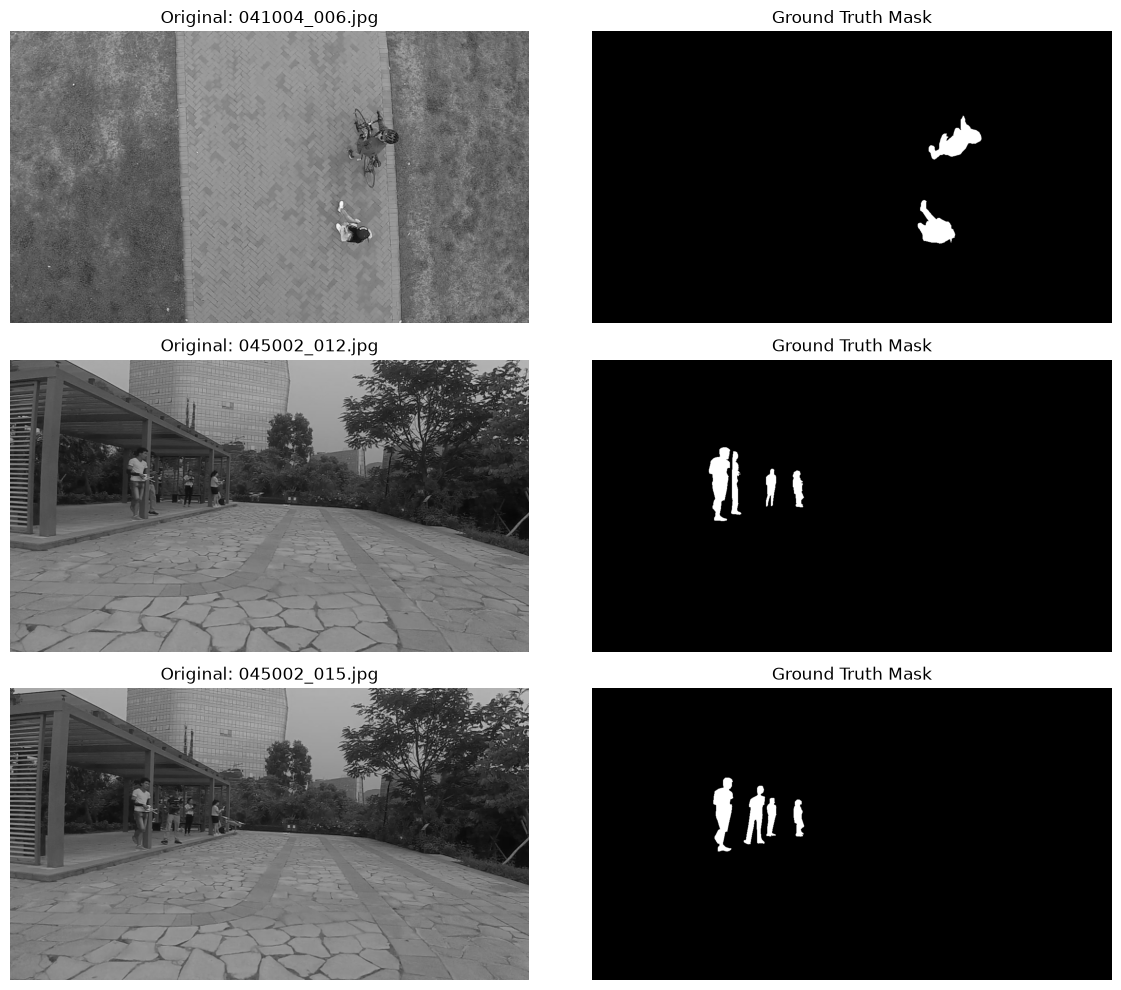

In [4]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

sample_rows = df.sample(3, random_state=42).reset_index(drop=True)
fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for idx, row in sample_rows.iterrows():
    img = Image.open(row["image_path"]).convert("RGB")
    mask = Image.open(row["mask_path"]).convert("L")
    axes[idx, 0].imshow(img)
    axes[idx, 0].set_title(f"Original: {row['file_name']}")
    axes[idx, 0].axis("off")
    axes[idx, 1].imshow(mask, cmap='gray')
    axes[idx, 1].set_title("Ground Truth Mask")
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()


### 4.2 Label Mapping

 Class ID Label Name  Raw Mask Value Visual Color
        0 Background               0        Black
        1     Person             255        White


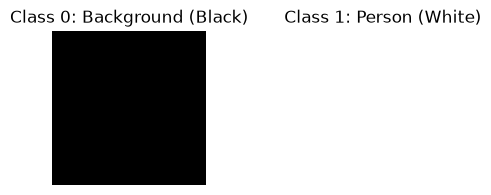

In [5]:
mapping_df = pd.DataFrame([
    {"Class ID": 0, "Label Name": "Background", "Raw Mask Value": 0,   "Visual Color": "Black"},
    {"Class ID": 1, "Label Name": "Person",     "Raw Mask Value": 255, "Visual Color": "White"},
])
print(mapping_df.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(6, 2))
ax[0].imshow(np.zeros((60, 60, 3), dtype=np.uint8))
ax[0].set_title("Class 0: Background (Black)")
ax[0].axis("off")
ax[1].imshow(np.ones((60, 60, 3), dtype=np.uint8) * 255)
ax[1].set_title("Class 1: Person (White)")
ax[1].axis("off")
plt.show()


### 4.3 Build DataLoaders

In [6]:
import torch

(
    train_dataset, val_dataset, test_dataset,
    train_loader,  val_loader,  test_loader,
) = build_dataloaders(train_df, val_df, test_df)

sample_img, sample_mask = train_dataset[0]
print(f"Input Image Tensor shape : {sample_img.shape}")
print(f"Target Mask Tensor shape : {sample_mask.shape}")
print(f"Unique classes in mask   : {torch.unique(sample_mask).tolist()}")
print(f"Batches  Train={len(train_loader)} | Val={len(val_loader)} | Test={len(test_loader)}")


Input Image Tensor shape : torch.Size([3, 256, 256])
Target Mask Tensor shape : torch.Size([256, 256])
Unique classes in mask   : [0, 1]
Batches  Train=44 | Val=5 | Test=5


## 5. MobileNetV3-UNet

In [7]:
from src.models    import build_mobileunet
from src.trainer   import train_model, plot_training_curves, compute_pos_weight
from src.metrics   import evaluate_model, print_eval_report
from src.visualise import visualise_predictions
import torch.nn as nn

model = build_mobileunet(device)


Downloading: "https://download.pytorch.org/models/lraspp_mobilenet_v3_large-d234d4ea.pth" to C:\Users\adith/.cache\torch\hub\checkpoints\lraspp_mobilenet_v3_large-d234d4ea.pth


100%|██████████| 12.5M/12.5M [00:07<00:00, 1.66MB/s]


MobileNetV3-UNet (LR-ASPP) initialised on: cuda


### 5.1 Train

In [8]:
model, unet_history = train_model(
    model         = model,
    train_loader  = train_loader,
    val_loader    = val_loader,
    train_dataset = train_dataset,
    device        = device,
    num_epochs    = UNET_EPOCHS,
    model_name    = "MobileNetV3-UNet",
    save_path     = str(UNET_CKPT),
)


Epoch [1/150] | Batch [10/44] | Batch Loss: 0.6145
Epoch [1/150] | Batch [20/44] | Batch Loss: 0.4878
Epoch [1/150] | Batch [30/44] | Batch Loss: 0.3937
Epoch [1/150] | Batch [40/44] | Batch Loss: 0.3296
Epoch [1/150] | Batch [44/44] | Batch Loss: 0.3301
---> Epoch [1/150] | Train Loss: 0.4869 | Train IoU: 0.0884 | Val Loss: 0.3303 | Val IoU: 0.1946

Epoch [2/150] | Batch [10/44] | Batch Loss: 0.2775
Epoch [2/150] | Batch [20/44] | Batch Loss: 0.2422
Epoch [2/150] | Batch [30/44] | Batch Loss: 0.2210
Epoch [2/150] | Batch [40/44] | Batch Loss: 0.1963
Epoch [2/150] | Batch [44/44] | Batch Loss: 0.1958
---> Epoch [2/150] | Train Loss: 0.2410 | Train IoU: 0.2325 | Val Loss: 0.1920 | Val IoU: 0.2229

Epoch [3/150] | Batch [10/44] | Batch Loss: 0.1930
Epoch [3/150] | Batch [20/44] | Batch Loss: 0.2203
Epoch [3/150] | Batch [30/44] | Batch Loss: 0.1580
Epoch [3/150] | Batch [40/44] | Batch Loss: 0.1580
Epoch [3/150] | Batch [44/44] | Batch Loss: 0.1605
---> Epoch [3/150] | Train Loss: 0.1716

### 5.2 Training Curves

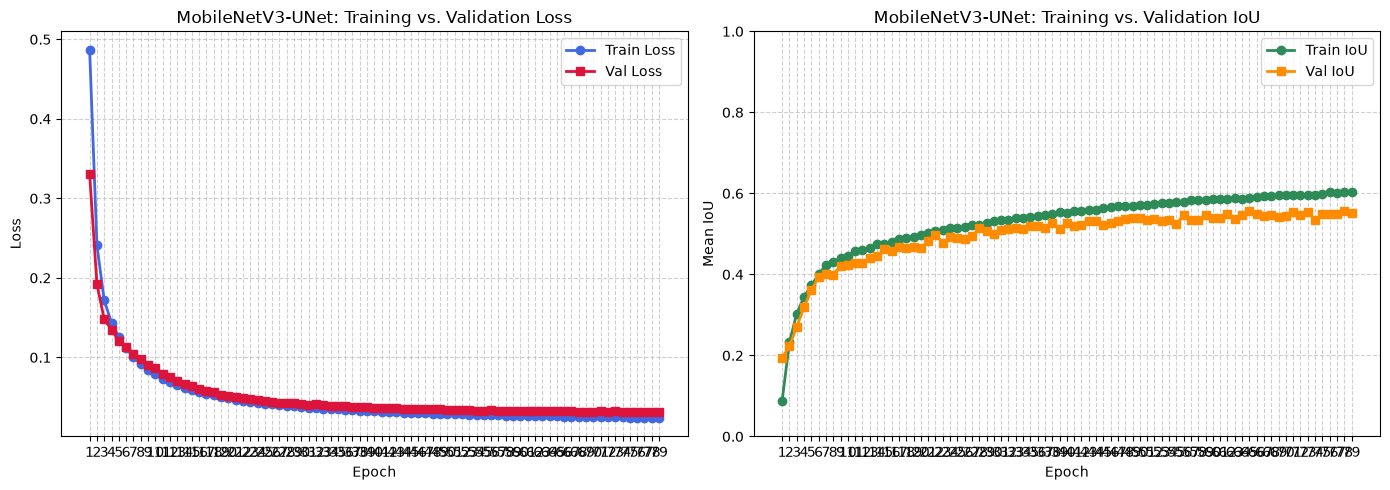

In [9]:
plot_training_curves(unet_history, model_name="MobileNetV3-UNet")


### 5.3 Evaluate

In [10]:
unet_criterion = nn.BCEWithLogitsLoss(
    pos_weight=compute_pos_weight(train_dataset, device)
)
unet_metrics = evaluate_model(
    model        = model,
    test_loader  = test_loader,
    test_dataset = test_dataset,
    criterion    = unet_criterion,
    device       = device,
)
print_eval_report(unet_metrics, model_name="MobileNetV3-UNet")


  MOBILENETV3-UNET EVALUATION REPORT (Test Set)
  Average Test Loss  : 0.0521
  Pixel Accuracy     : 99.12%
  Mean IoU (Person)  : 0.5324
  Precision (Person) : 0.5790
  Recall    (Person) : 0.8497
  Dice / F1 (Person) : 0.6887


### 5.4 Inference Visualisation

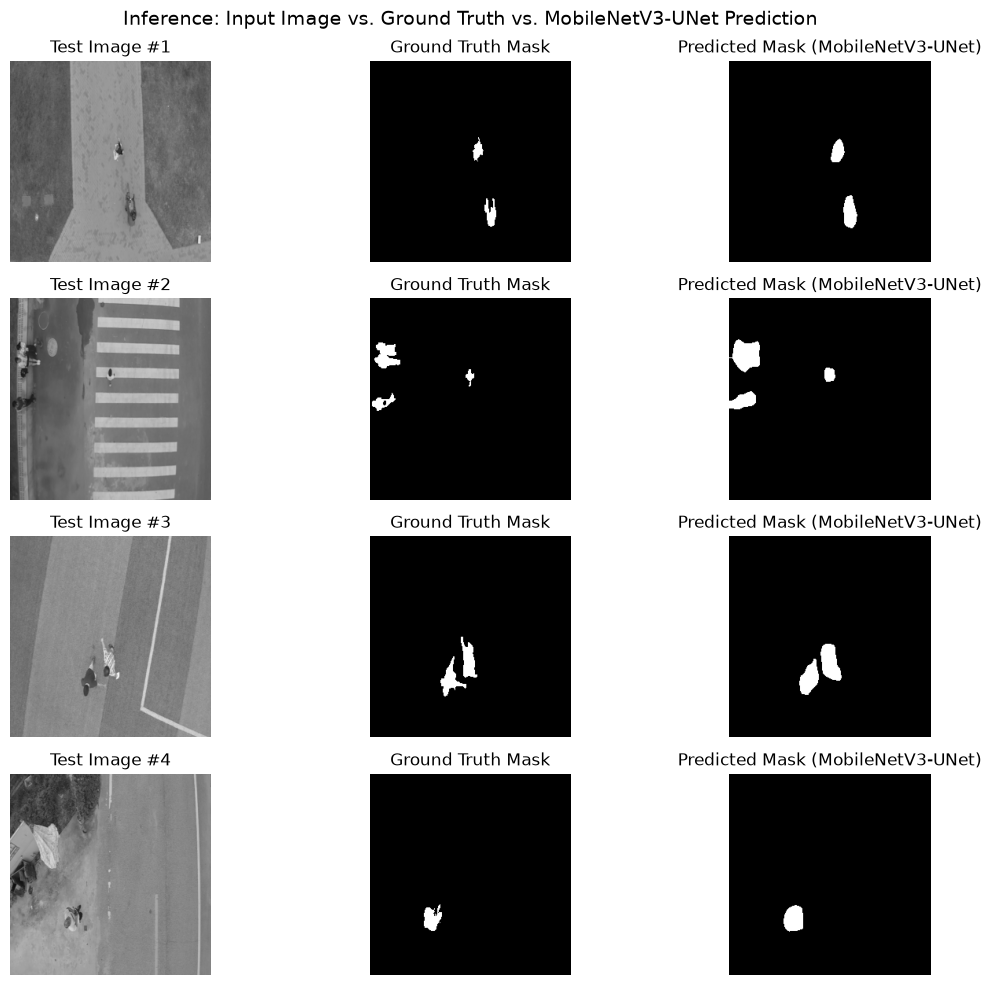

In [11]:
visualise_predictions(model, test_dataset, device, model_name="MobileNetV3-UNet")


## 6. Feature Pyramid Network (FPN)

In [12]:
from src.models import build_fpn

fpn_model = build_fpn(device)


c:\Users\adith\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FPN (ResNet34, smp) initialised on: cuda


### 6.1 Train

In [13]:
fpn_model, fpn_history = train_model(
    model         = fpn_model,
    train_loader  = train_loader,
    val_loader    = val_loader,
    train_dataset = train_dataset,
    device        = device,
    num_epochs    = FPN_EPOCHS,
    model_name    = "FPN",
    save_path     = str(FPN_CKPT),
)


Epoch [1/50] | Batch [10/44] | Batch Loss: 0.1972
Epoch [1/50] | Batch [20/44] | Batch Loss: 0.1034
Epoch [1/50] | Batch [30/44] | Batch Loss: 0.0543
Epoch [1/50] | Batch [40/44] | Batch Loss: 0.0662
Epoch [1/50] | Batch [44/44] | Batch Loss: 0.0755
---> Epoch [1/50] | Train Loss: 0.1339 | Train IoU: 0.2137 | Val Loss: 0.0677 | Val IoU: 0.3495

Epoch [2/50] | Batch [10/44] | Batch Loss: 0.0463
Epoch [2/50] | Batch [20/44] | Batch Loss: 0.0606
Epoch [2/50] | Batch [30/44] | Batch Loss: 0.0505
Epoch [2/50] | Batch [40/44] | Batch Loss: 0.0526
Epoch [2/50] | Batch [44/44] | Batch Loss: 0.0409
---> Epoch [2/50] | Train Loss: 0.0548 | Train IoU: 0.3983 | Val Loss: 0.0469 | Val IoU: 0.4568

Epoch [3/50] | Batch [10/44] | Batch Loss: 0.0400
Epoch [3/50] | Batch [20/44] | Batch Loss: 0.0395
Epoch [3/50] | Batch [30/44] | Batch Loss: 0.0422
Epoch [3/50] | Batch [40/44] | Batch Loss: 0.0416
Epoch [3/50] | Batch [44/44] | Batch Loss: 0.0381
---> Epoch [3/50] | Train Loss: 0.0426 | Train IoU: 0.46

### 6.2 Training Curves

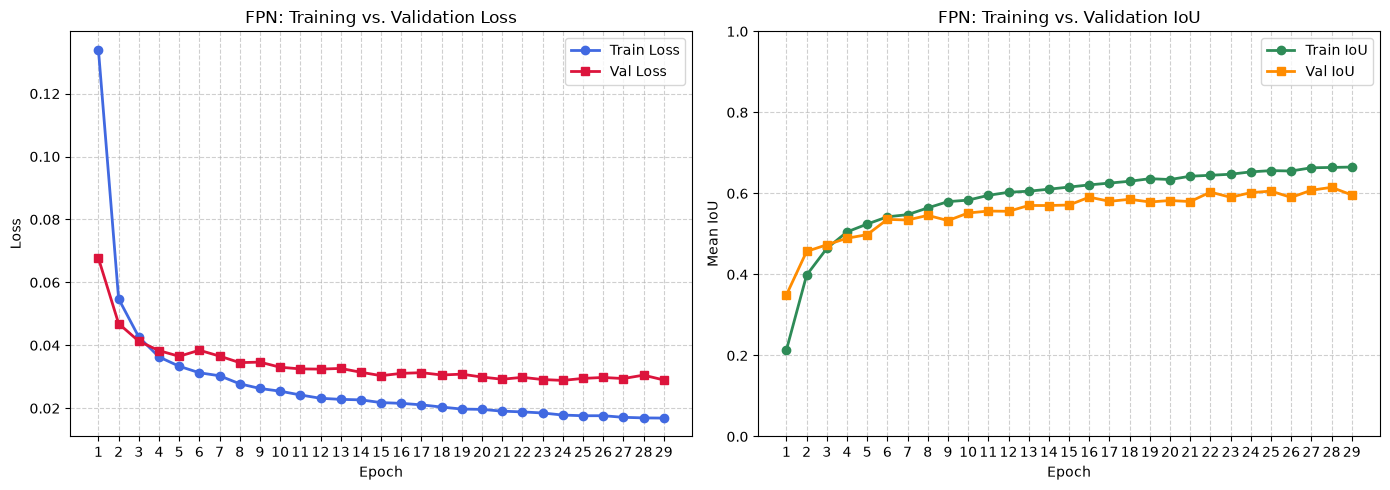

In [14]:
plot_training_curves(fpn_history, model_name="FPN")


### 6.3 Evaluate

  FPN EVALUATION REPORT (Test Set)
  Average Test Loss  : 0.0488
  Pixel Accuracy     : 99.33%
  Mean IoU (Person)  : 0.6030
  Precision (Person) : 0.6635
  Recall    (Person) : 0.8379
  Dice / F1 (Person) : 0.7406


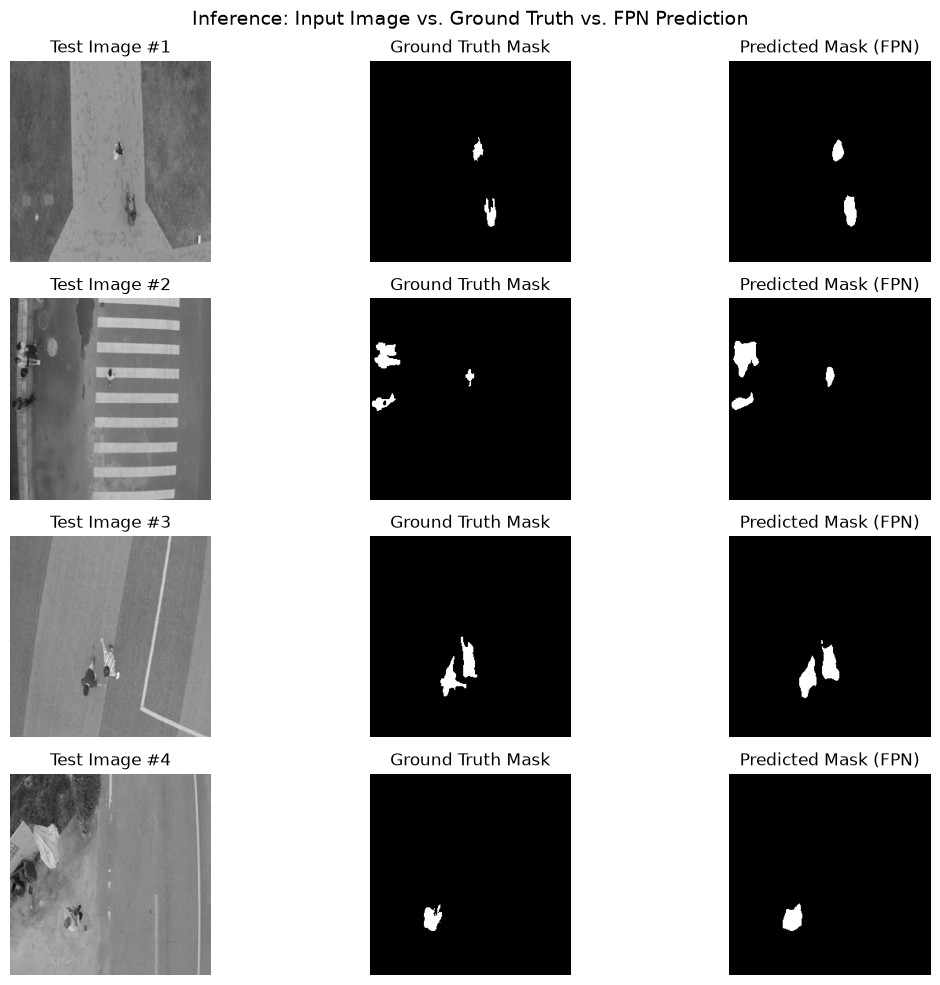

In [15]:
fpn_criterion = nn.BCEWithLogitsLoss(
    pos_weight=compute_pos_weight(train_dataset, device)
)
fpn_metrics = evaluate_model(
    model        = fpn_model,
    test_loader  = test_loader,
    test_dataset = test_dataset,
    criterion    = fpn_criterion,
    device       = device,
)
print_eval_report(fpn_metrics, model_name="FPN")
visualise_predictions(fpn_model, test_dataset, device, model_name="FPN")


## 7. SAM 2 Segmentation Model

In [16]:
from src.models import build_sam2

sam2_model = build_sam2(device)


SAM2 (DeepLabV3 + MobileNetV3-Large) initialised on: cuda


### 7.1 Train

In [17]:
sam2_model, sam2_history = train_model(
    model         = sam2_model,
    train_loader  = train_loader,
    val_loader    = val_loader,
    train_dataset = train_dataset,
    device        = device,
    num_epochs    = SAM2_EPOCHS,
    model_name    = "SAM 2",
    save_path     = str(SAM2_CKPT),
)


Epoch [1/150] | Batch [10/44] | Batch Loss: 0.6359
Epoch [1/150] | Batch [20/44] | Batch Loss: 0.5512
Epoch [1/150] | Batch [30/44] | Batch Loss: 0.4648
Epoch [1/150] | Batch [40/44] | Batch Loss: 0.4025
Epoch [1/150] | Batch [44/44] | Batch Loss: 0.4218
---> Epoch [1/150] | Train Loss: 0.5420 | Train IoU: 0.1082 | Val Loss: 0.4302 | Val IoU: 0.1594

Epoch [2/150] | Batch [10/44] | Batch Loss: 0.3024
Epoch [2/150] | Batch [20/44] | Batch Loss: 0.2802
Epoch [2/150] | Batch [30/44] | Batch Loss: 0.2504
Epoch [2/150] | Batch [40/44] | Batch Loss: 0.2207
Epoch [2/150] | Batch [44/44] | Batch Loss: 0.2355
---> Epoch [2/150] | Train Loss: 0.2786 | Train IoU: 0.2319 | Val Loss: 0.2389 | Val IoU: 0.2322

Epoch [3/150] | Batch [10/44] | Batch Loss: 0.2106
Epoch [3/150] | Batch [20/44] | Batch Loss: 0.1957
Epoch [3/150] | Batch [30/44] | Batch Loss: 0.1729
Epoch [3/150] | Batch [40/44] | Batch Loss: 0.1527
Epoch [3/150] | Batch [44/44] | Batch Loss: 0.1799
---> Epoch [3/150] | Train Loss: 0.1945

### 7.2 Training Curves

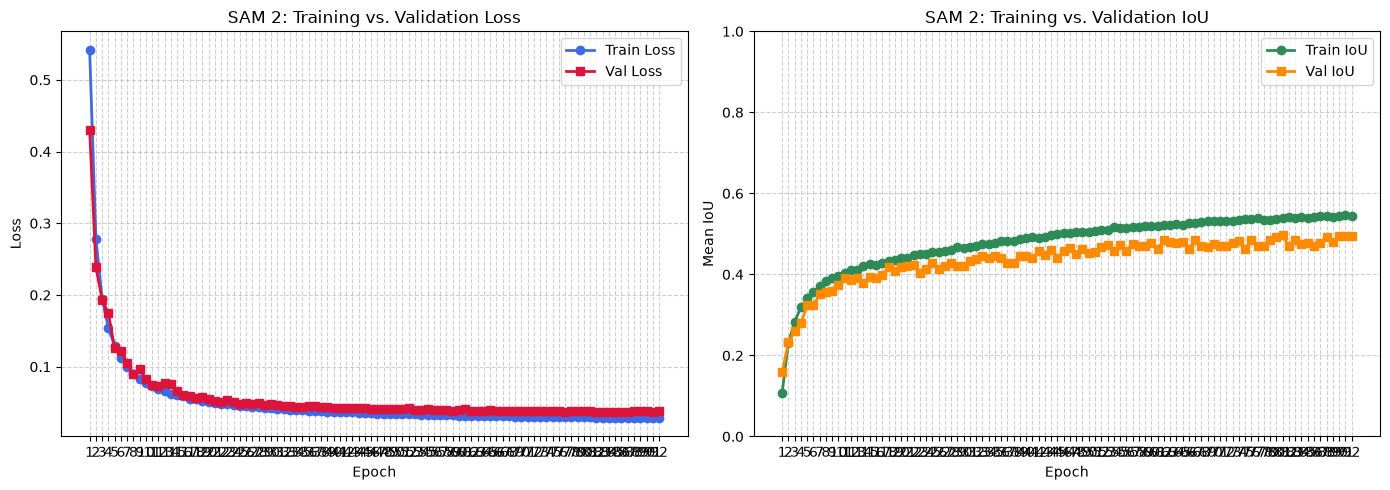

In [18]:
plot_training_curves(sam2_history, model_name="SAM 2")


### 7.3 Evaluate

  SAM 2 EVALUATION REPORT (Test Set)
  Average Test Loss  : 0.0615
  Pixel Accuracy     : 98.96%
  Mean IoU (Person)  : 0.4850
  Precision (Person) : 0.5276
  Recall    (Person) : 0.8114
  Dice / F1 (Person) : 0.6394


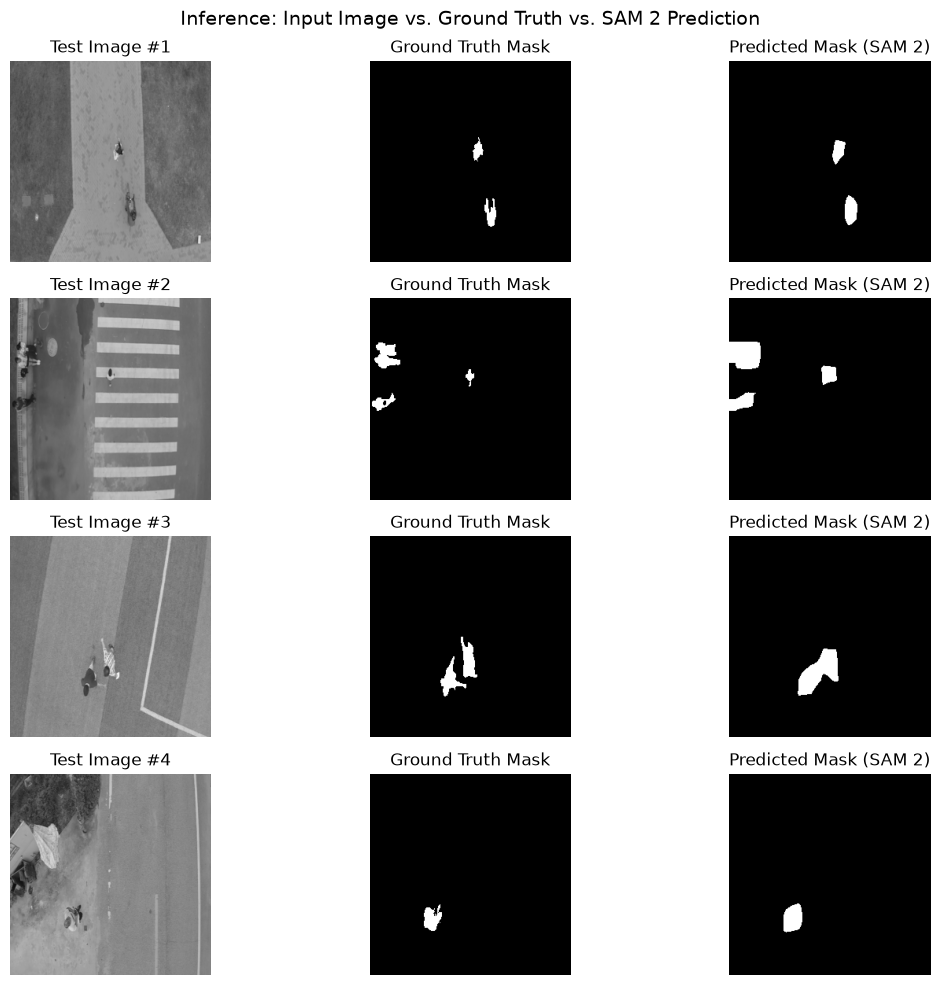

In [19]:
sam2_criterion = nn.BCEWithLogitsLoss(
    pos_weight=compute_pos_weight(train_dataset, device)
)
sam2_metrics = evaluate_model(
    model        = sam2_model,
    test_loader  = test_loader,
    test_dataset = test_dataset,
    criterion    = sam2_criterion,
    device       = device,
)
print_eval_report(sam2_metrics, model_name="SAM 2")
visualise_predictions(sam2_model, test_dataset, device, model_name="SAM 2")


## 8. FCN (ResNet50)

In [20]:
from src.models import build_fcn

fcn_model = build_fcn(device)


FCN (ResNet50) initialised on: cuda


### 8.1 Train

In [21]:
fcn_model, fcn_history = train_model(
    model         = fcn_model,
    train_loader  = train_loader,
    val_loader    = val_loader,
    train_dataset = train_dataset,
    device        = device,
    num_epochs    = FCN_EPOCHS,
    model_name    = "FCN",
    save_path     = str(FCN_CKPT),
)


Epoch [1/150] | Batch [10/44] | Batch Loss: 0.3931
Epoch [1/150] | Batch [20/44] | Batch Loss: 0.3199
Epoch [1/150] | Batch [30/44] | Batch Loss: 0.3137
Epoch [1/150] | Batch [40/44] | Batch Loss: 0.2672
Epoch [1/150] | Batch [44/44] | Batch Loss: 0.2546
---> Epoch [1/150] | Train Loss: 0.3543 | Train IoU: 0.2841 | Val Loss: 0.2634 | Val IoU: 0.3930

Epoch [2/150] | Batch [10/44] | Batch Loss: 0.2305
Epoch [2/150] | Batch [20/44] | Batch Loss: 0.2120
Epoch [2/150] | Batch [30/44] | Batch Loss: 0.1993
Epoch [2/150] | Batch [40/44] | Batch Loss: 0.1794
Epoch [2/150] | Batch [44/44] | Batch Loss: 0.1777
---> Epoch [2/150] | Train Loss: 0.2078 | Train IoU: 0.4261 | Val Loss: 0.1833 | Val IoU: 0.4441

Epoch [3/150] | Batch [10/44] | Batch Loss: 0.1649
Epoch [3/150] | Batch [20/44] | Batch Loss: 0.1619
Epoch [3/150] | Batch [30/44] | Batch Loss: 0.1450
Epoch [3/150] | Batch [40/44] | Batch Loss: 0.1347
Epoch [3/150] | Batch [44/44] | Batch Loss: 0.1392
---> Epoch [3/150] | Train Loss: 0.1536

### 8.2 Training Curves

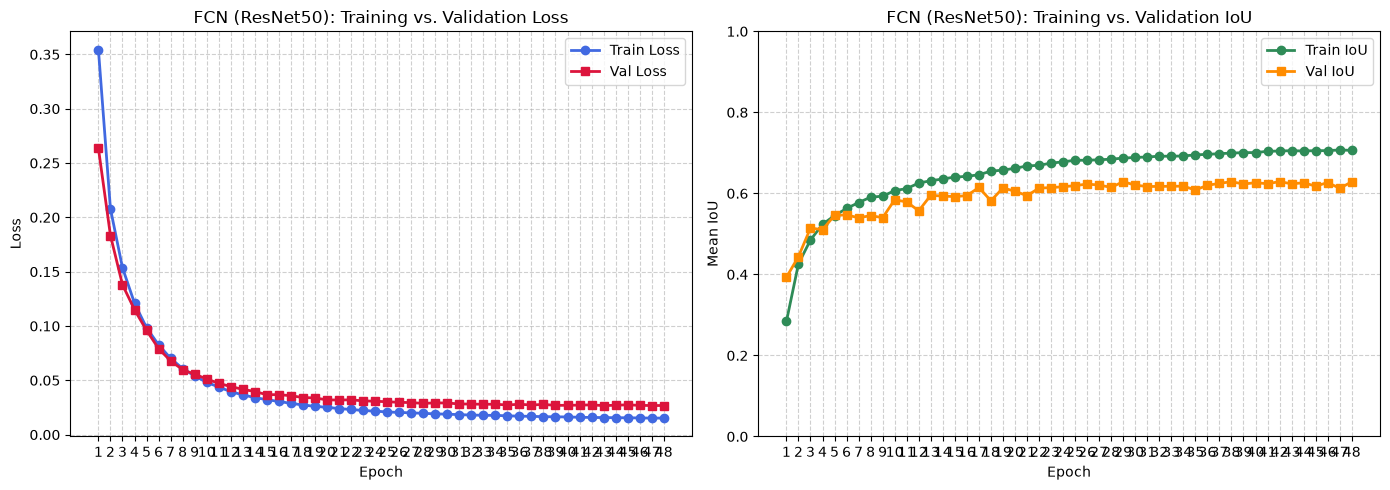

In [22]:
plot_training_curves(fcn_history, model_name="FCN (ResNet50)")


### 8.3 Evaluate

  FCN (RESNET50) EVALUATION REPORT (Test Set)
  Average Test Loss  : 0.0485
  Pixel Accuracy     : 99.37%
  Mean IoU (Person)  : 0.6252
  Precision (Person) : 0.6834
  Recall    (Person) : 0.8426
  Dice / F1 (Person) : 0.7547


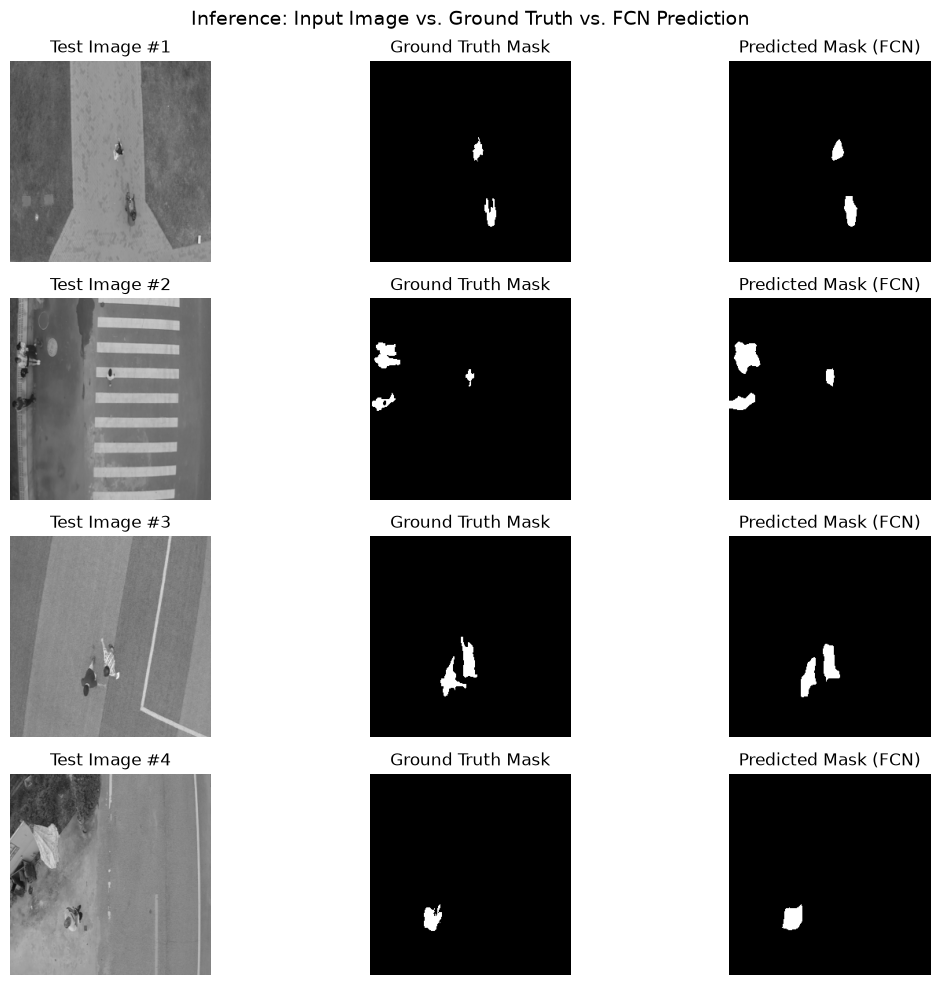

In [23]:
fcn_criterion = nn.BCEWithLogitsLoss(
    pos_weight=compute_pos_weight(train_dataset, device)
)
fcn_metrics = evaluate_model(
    model        = fcn_model,
    test_loader  = test_loader,
    test_dataset = test_dataset,
    criterion    = fcn_criterion,
    device       = device,
)
print_eval_report(fcn_metrics, model_name="FCN (ResNet50)")
visualise_predictions(fcn_model, test_dataset, device, model_name="FCN")


## 9. Comprehensive Model Benchmark Comparison

                    MODEL BENCHMARK COMPARISON TABLE
           Model  Pixel Accuracy (%)  Mean IoU  Dice / F1  Precision  Recall
MobileNetV3-UNet               99.12    0.5324     0.6887     0.5790  0.8497
  FPN (ResNet34)               99.33    0.6030     0.7406     0.6635  0.8379
           SAM 2               98.96    0.4850     0.6394     0.5276  0.8114
  FCN (ResNet50)               99.37    0.6252     0.7547     0.6834  0.8426


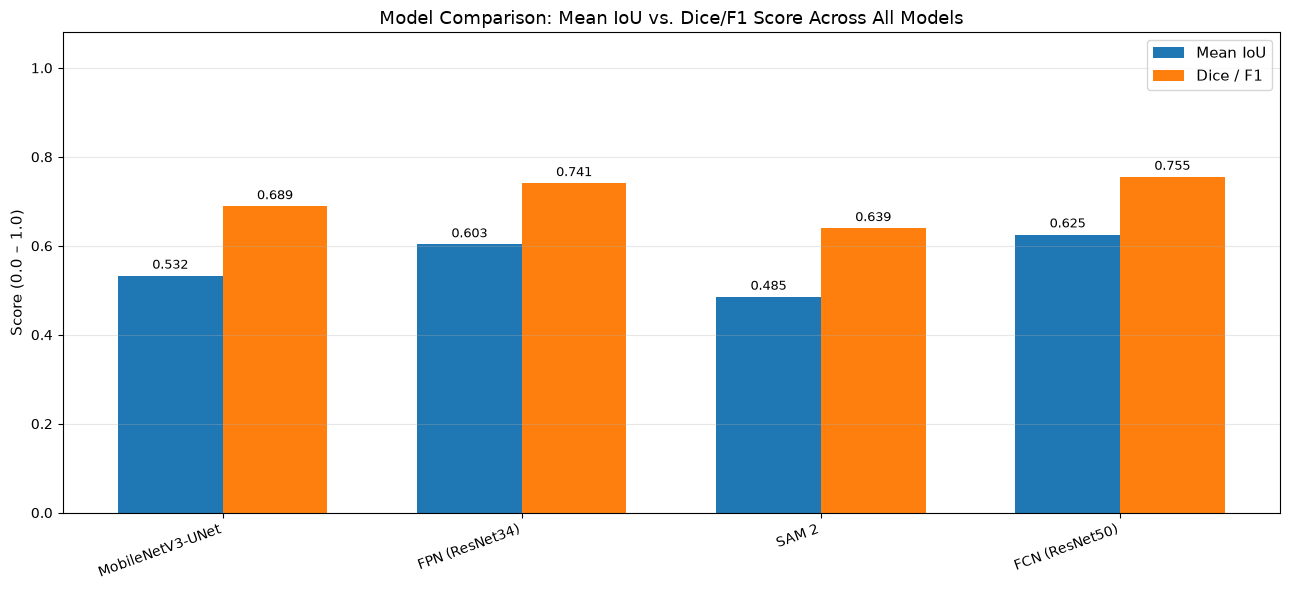

,Model,Pixel Accuracy (%),Mean IoU,Dice / F1,Precision,Recall
0,MobileNetV3-UNet,99.12,0.5324,0.6887,0.5790,0.8497
1,FPN (ResNet34),99.33,0.6030,0.7406,0.6635,0.8379
2,SAM 2,98.96,0.4850,0.6394,0.5276,0.8114
3,FCN (ResNet50),99.37,0.6252,0.7547,0.6834,0.8426


In [24]:
from src.visualise import plot_benchmark_comparison

all_metrics = {
    "MobileNetV3-UNet": unet_metrics,
    "FPN (ResNet34)":   fpn_metrics,
    "SAM 2":            sam2_metrics,
    "FCN (ResNet50)":   fcn_metrics,
}

comparison_df = plot_benchmark_comparison(all_metrics)
comparison_df
